# Qu'est-ce qui explique le prix du gazole d'une station ?

**Question.** Les caractéristiques d'une station (position, autoroute, services, nombre de stations du département) expliquent-elles son prix du gazole ?

**Données.** Dernier relevé de la table gold du projet carburants, une ligne par station : 8 877 stations après nettoyage.

**Méthode.**
1. Charger et nettoyer les données.
2. Construire 29 variables explicatives, sans jamais utiliser le prix.
3. Mettre de côté 20 départements pour un test final, puis comparer les modèles par validation croisée par département sur les 76 autres.
4. Baseline (prix moyen), arbre de régression, forêt aléatoire. Choix : l'arbre, lisible et presque aussi bon.
5. Évaluer l'arbre une seule fois sur le test final, puis l'expliquer avec SHAP.

**Résultat en une ligne.** Sur 20 départements jamais vus, l'arbre se trompe en moyenne de 5,4 centimes, contre 5,9 pour la moyenne nationale (R² 0,19). Les caractéristiques de la station n'expliquent donc qu'une petite partie du prix.

## 1. Charger les données

**Connexion à PostgreSQL.** Les identifiants sont lus dans le fichier `.env` (`DB_USER`, `DB_PASSWORD`, `DB_NAME`...), jamais écrits dans le code. `URL.create` construit l'adresse de connexion et gère les caractères spéciaux du mot de passe. `engine` est l'objet qui sait parler à la base.

In [1]:
import os
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy.engine import URL
from sqlalchemy import create_engine, text


load_dotenv()

engine = create_engine(
    URL.create(
        "postgresql+psycopg2",
        username=os.getenv("DB_USER"),
        password=os.getenv("DB_PASSWORD"),
        host=os.getenv("DB_HOST", "localhost"),
        port=int(os.getenv("DB_PORT", "5432")),
        database=os.getenv("DB_NAME"),
    )
)

**Requête SQL.** On ne garde que le gazole, uniquement pour le dernier relevé (`snapshot_date = max(...)`), avec une seule ligne par station (`distinct on (id)`). Sans ces deux filtres, une station apparaîtrait une fois par date. Le résultat est rangé dans `df`, un tableau pandas.

In [2]:
TABLE = "gold.gold_stations_prices"   # remplace par le nom exact de ta table gold

query = f"""
select distinct on (id)
    id, code_departement, type_station, services,
    latitude, longitude, prix
from {TABLE}
where carburant = 'gazole'
  and snapshot_date = (select max(snapshot_date) from {TABLE})
order by id
"""

with engine.connect() as conn:
    df = pd.read_sql(text(query), conn)

**Premier contrôle.** 8 882 lignes et 7 colonnes. La colonne `services` est un texte qui ressemble à une liste (`["Station de gonflage", ...]`) : on devra la lire avec `json` à l'étape 3.

In [3]:
print(df.shape)
df.head()

(8882, 7)


,id,code_departement,type_station,services,latitude,longitude,prix
0,1000001,01,R,"[""Station de gonflage"", ""Vente de gaz domestiq...",46.20100,5.19800,2.413
1,1000002,01,R,"[""Vente de gaz domestique (Butane, Propane)"", ...",46.21842,5.22767,2.409
2,1000007,01,R,"[""Vente de pétrole lampant"", ""Station de gonfl...",46.22100,5.24500,2.409
3,1000008,01,R,"[""Toilettes publiques"", ""Laverie"", ""Relais col...",46.19900,5.24100,2.409
4,1000009,01,R,"[""Laverie"", ""Boutique alimentaire"", ""Boutique ...",46.19600,5.22900,2.413


## 2. Explorer et nettoyer

**Valeurs manquantes.** 4 stations n'ont pas de département et 613 n'ont aucun service. Ces dernières ne sont pas une erreur : elles n'ont simplement déclaré aucun service.

In [4]:
df.isna().sum()

id                    0
code_departement      4
type_station          0
services            613
latitude              0
longitude             0
prix                  0
dtype: int64

**Résumé du prix.** Moyenne 2,370 € et médiane 2,369 € presque identiques ; la moitié des stations est entre 2,335 € et 2,400 €. Les prix sont donc très serrés (écart-type de 8 centimes), et le modèle devra expliquer des écarts de quelques centimes. Le minimum (1,381 €) et le maximum (2,900 €) sont à regarder de près.

In [5]:
df["prix"].describe()

count    8882.000000
mean        2.369734
std         0.082641
min         1.381000
25%         2.335000
50%         2.369000
75%         2.400000
max         2.900000
Name: prix, dtype: float64

**Deux corrections sûres.** On retire les 4 stations sans département (il en faut un pour le découpage par département) et on remplace les services manquants par un texte vide. Il reste 8 878 lignes.

In [6]:
df = df.dropna(subset=["code_departement"]).copy()
df["services"] = df["services"].fillna("")
df.shape

(8878, 7)

**Les 10 prix les plus bas.** Une seule station est isolée : 1,381 € (département 01, avec pour seul service un automate CB), alors que la suivante est à 2,090 €. Les suivantes (dont plusieurs en Corse) sont bien plus proches les unes des autres.

In [7]:
df.sort_values("prix").head(10)


,id,code_departement,type_station,services,latitude,longitude,prix
57,1380002,01,R,"[""Automate CB 24/24""]",46.313000,4.941000,1.381
3782,40600005,40,R,,44.441340,-1.241538,2.090
8549,91630008,91,R,"[""Station de gonflage"", ""Carburant additivé"", ...",48.568000,2.232000,2.109
2503,29870004,29,R,"[""Station de gonflage"", ""Services réparation /...",48.573856,-4.534119,2.190
1666,20270003,2B,R,"[""Toilettes publiques"", ""Relais colis"", ""Bouti...",42.115000,9.514000,2.190
1617,20189002,2A,R,"[""Boutique alimentaire"", ""Boutique non aliment...",41.927000,8.784000,2.195
1607,20167004,2A,R,"[""Toilettes publiques"", ""Relais colis"", ""Bouti...",41.965000,8.782000,2.199
1562,20000006,2A,R,"[""Laverie"", ""Boutique alimentaire"", ""Boutique ...",41.929000,8.765000,2.199
1656,20243001,2B,R,"[""Toilettes publiques"", ""Boutique alimentaire""...",41.998686,9.402860,2.200
7026,75017019,75,R,"[""Boutique non alimentaire"", ""Carburant additi...",48.890455,2.303319,2.200


**Les 10 prix les plus hauts.** Un mélange d'aires d'autoroute (type `A`, avec douches et boutique) et de stations routières (Var, Alpes-Maritimes, Paris...). Ces prix semblent plausibles et portent une information que le modèle doit apprendre : on les garde.

In [8]:
df.sort_values("prix").tail(10)

,id,code_departement,type_station,services,latitude,longitude,prix
7935,83990002,83,R,"[""Boutique alimentaire"", ""Boutique non aliment...",43.26700,6.63000,2.780
468,6650003,06,R,"[""Lavage automatique"", ""Lavage manuel"", ""DAB (...",43.66800,6.98500,2.790
1441,17800005,17,A,"[""Toilettes publiques"", ""Douches"", ""Boutique a...",45.61300,-0.60400,2.799
2327,28160008,28,A,"[""Toilettes publiques"", ""Douches"", ""Boutique a...",48.24100,1.08400,2.799
6228,67540003,67,A,"[""Toilettes publiques"", ""Douches"", ""Boutique a...",48.53900,7.71700,2.817
4501,49480005,49,A,"[""Toilettes publiques"", ""Douches"", ""Relais col...",47.50000,-0.49100,2.819
6314,68390002,68,R,"[""Toilettes publiques"", ""Douches"", ""Boutique a...",47.77700,7.37900,2.827
8104,85350001,85,R,"[""DAB (Distributeur automatique de billets)""]",46.72342,-2.34468,2.829
6229,67540006,67,A,"[""Toilettes publiques"", ""Douches"", ""Relais col...",48.53900,7.71700,2.876
6998,75007003,75,R,"[""Boutique non alimentaire"", ""Station de gonfl...",48.85300,2.30800,2.900


**Valeurs éloignées de la médiane.** 64 stations (0,7 %) sont à plus de 30 centimes de la médiane. C'est peu, et ces stations sont de natures variées (autoroutes, zones touristiques, urbaines) : à part la station à 1,381 € traitée juste après, on ne retire rien.

In [9]:
mediane = df["prix"].median()
loin = df[(df["prix"] - mediane).abs() > 0.30]
print(len(loin))
loin

64


,id,code_departement,type_station,services,latitude,longitude,prix
57,1380002,01,R,"[""Automate CB 24/24""]",46.313000,4.941000,1.381
240,3400005,03,R,"[""Piste poids lourds"", ""Vente d'additifs carbu...",46.506387,3.361722,2.680
405,6250012,06,A,"[""Toilettes publiques"", ""Douches"", ""Boutique a...",43.592040,7.036158,2.693
468,6650003,06,R,"[""Lavage automatique"", ""Lavage manuel"", ""DAB (...",43.668000,6.985000,2.790
1010,13340005,13,R,"[""Piste poids lourds"", ""Vente d'additifs carbu...",43.496204,5.214500,2.680
...,...,...,...,...,...,...,...
7651,80970003,80,A,"[""Toilettes publiques"", ""Douches"", ""Boutique a...",50.167000,1.755000,2.697
7935,83990002,83,R,"[""Boutique alimentaire"", ""Boutique non aliment...",43.267000,6.630000,2.780
8104,85350001,85,R,"[""DAB (Distributeur automatique de billets)""]",46.723420,-2.344680,2.829
8237,87160008,87,A,"[""Toilettes publiques"", ""Douches"", ""Boutique n...",46.313794,1.420283,2.710


**Forme des prix.** Une grande bosse centrée sur 2,37 € et, à côté, un pic étroit vers 2,25 € qui regroupe beaucoup de stations.

<Axes: >

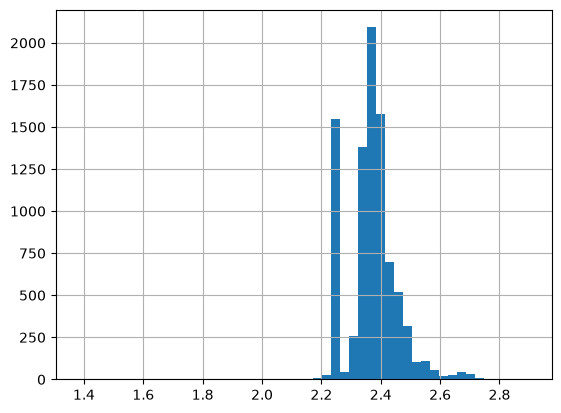

In [10]:
df["prix"].hist(bins=50)

**Décision : retirer la station à 1,381 €.** On garde les prix à partir de 2,0 €, ce qui retire cette seule station (probable erreur de saisie : presque un euro sous la médiane, 71 centimes sous la suivante). Il reste 8 877 stations. À noter dans le README.

In [11]:
df = df[df["prix"] >= 2.0].copy()
df.shape

(8877, 7)

**Le pic à 2,25 €.** 1 501 stations affichent exactement 2,250 €, presque trois fois plus que le prix suivant (2,399 € : 547 stations). C'est un prix « rond », alors que les autres prix fréquents finissent surtout par 9 (2,399, 2,369, 2,359...).

In [12]:
df["prix"].value_counts().head(10)

prix
2.250    1501
2.399     547
2.369     454
2.359     402
2.349     383
2.379     351
2.389     284
2.339     230
2.449     209
2.329     153
Name: count, dtype: int64

**Qui sont ces stations ?** 1 388 sont sur route et 113 sur autoroute. Les départements en tête (13, 78, 77, 59...) sont simplement ceux qui ont le plus de stations : le pic n'est pas régional.

In [13]:
pic = df[df["prix"] == 2.25]
print(len(pic))
print(pic["type_station"].value_counts())
print(pic["code_departement"].value_counts().head(10))

1501
type_station
R    1388
A     113
Name: count, dtype: int64
code_departement
13    59
78    51
77    44
59    43
69    41
33    40
95    36
06    34
34    30
44    30
Name: count, dtype: int64


**Part d'autoroute.** 4,8 % de toutes les stations, mais 7,5 % de celles à 2,25 € (113 sur 1 501) : une légère sur-représentation, sans que ça explique le pic. Hypothèse : une politique de prix commune à une enseigne, mais notre table n'a pas l'enseigne, donc on ne peut pas le vérifier. On garde ces stations (17 % des données) et on l'écrit comme une limite.

In [14]:
df["type_station"].value_counts(normalize=True)

type_station
R    0.951786
A    0.048214
Name: proportion, dtype: float64

Étape 3 : créer les variables explicatives

lire_services transforme le texte en vraie liste Python (ou en liste vide s’il n’y a rien).
nb_services compte les éléments de la liste.

Je compte avec json et non avec les virgules, parce que certains services en contiennent une (par exemple « Vente de gaz domestique (Butane, Propane) »). Le script que je t’avais donné faisait cette erreur : on le corrigera à la fin.

 : (1) aucune variable n'est calculée à partir du prix, sinon le modèle « triche » (fuite d'information) ; (2) le code du département n'est pas transformé en nombre (le 13 n'est pas « entre » le 12 et le 14). La latitude, la longitude et le nombre de stations du département suffisent.

**Lire et compter les services.** `json.loads` transforme le texte en vraie liste Python. On ne compte pas avec les virgules, car certains noms de services en contiennent (« Vente de gaz domestique (Butane, Propane) »). `nb_services` varie de 0 à 24, avec une médiane de 6.

In [15]:
#lire et compter les services
import json

def lire_services(texte):
    return json.loads(texte) if texte else []

df["liste_services"] = df["services"].apply(lire_services)
df["nb_services"] = df["liste_services"].apply(len)
df["nb_services"].describe()


count    8877.000000
mean        6.354061
std         4.446165
min         0.000000
25%         3.000000
50%         6.000000
75%         9.000000
max        24.000000
Name: nb_services, dtype: float64

**Quels services existent ?** `Counter` compte combien de stations proposent chaque service. Les plus courants : gaz domestique (5 513 stations), automate CB 24/24 (5 130), gonflage (4 741).

In [16]:
#quels services existent ?
from collections import Counter

compteur = Counter(s for liste in df["liste_services"] for s in liste)
compteur.most_common(15)


[('Vente de gaz domestique (Butane, Propane)', 5513),
 ('Automate CB 24/24', 5130),
 ('Station de gonflage', 4741),
 ('DAB (Distributeur automatique de billets)', 3738),
 ('Piste poids lourds', 3701),
 ('Boutique alimentaire', 3685),
 ('Boutique non alimentaire', 3020),
 ('Lavage automatique', 2964),
 ('Carburant additivé', 2751),
 ('Toilettes publiques', 2383),
 ('Lavage manuel', 2260),
 ('Relais colis', 1857),
 ('Laverie', 1813),
 ('Restauration à emporter', 1788),
 ('Location de véhicule', 1710)]

une colonne 0 ou 1 par service courant
On garde les services proposés par au moins 5 % des stations : les plus rares donneraient des colonnes presque toujours à 0, qui n’apprennent rien au modèle.
Pour chacun, une colonne vaut 1 si la station le propose, 0 sinon.

**Une colonne 0/1 par service courant.** On garde les services proposés par au moins 5 % des stations : les plus rares donneraient des colonnes presque toujours à 0, qui n'apprennent rien. Cela donne 24 colonnes.

In [17]:
frequents = [nom for nom, n in compteur.items() if n >= 0.05 * len(df)]

for nom in frequents:
    df["service_" + nom] = df["liste_services"].apply(lambda liste: int(nom in liste))

frequents

['Station de gonflage',
 'Vente de gaz domestique (Butane, Propane)',
 'DAB (Distributeur automatique de billets)',
 'Vente de pétrole lampant',
 'Lavage automatique',
 'Lavage manuel',
 'Automate CB 24/24',
 'Toilettes publiques',
 'Laverie',
 'Relais colis',
 'Boutique alimentaire',
 'Boutique non alimentaire',
 'Restauration à emporter',
 'Restauration sur place',
 'Bar',
 'Carburant additivé',
 'Location de véhicule',
 'Piste poids lourds',
 'Services réparation / entretien',
 'Bornes électriques',
 "Vente d'additifs carburants",
 'Wifi',
 'Vente de fioul domestique',
 'Espace bébé']

**Deux autres variables.** `is_autoroute` vaut 1 pour une autoroute (`A`). `nb_stations_dept` compte les stations du département (une idée de la concurrence locale), sans utiliser le prix.

In [18]:
df["is_autoroute"] = (df["type_station"] == "A").astype(int)
df["nb_stations_dept"] = df.groupby("code_departement")["id"].transform("count")

is_autoroute vaut 1 pour une autoroute (A), 0 sinon.
nb_stations_dept compte les stations du département de chaque station.

assembler X et y

**Assemblage.** `X` (8 877 × 29) : latitude, longitude, `is_autoroute`, `nb_services`, `nb_stations_dept` et les 24 services. `y` est le prix, la cible. `groupes` garde le département de chaque station : il sert seulement à découper, le modèle ne le voit pas.

In [19]:
colonnes_services = [c for c in df.columns if c.startswith("service_")]
colonnes = ["latitude", "longitude", "is_autoroute", "nb_services", "nb_stations_dept"] + colonnes_services

X = df[colonnes]
y = df["prix"]
groupes = df["code_departement"]

X.shape

(8877, 29)

Étape 4 : séparer entraînement et test
Le concept

Un modèle doit être jugé sur des données qu’il n’a jamais vues, sinon il peut simplement les avoir apprises par cœur. On met donc de côté une partie des stations (le test) et on entraîne sur le reste.

Le piège, c’est la façon de découper. Si on tire des stations au hasard, une station du test a presque toujours une voisine dans l’entraînement, avec un prix très proche. Le modèle réussit alors en recopiant ses voisines, et le score est trop beau. Pour l’éviter, on découpe par département : tous les stations d’un département sont soit dans l’entraînement, soit dans le test, jamais des deux côtés. C’est ce que fait GroupKFold.

On répète cinq fois, en changeant de groupe de test à chaque tour (validation croisée). Chaque station est testée une fois.

Un modèle doit être jugé sur des données qu'il n'a jamais vues. Le piège : si on tire des stations au hasard, une station du test a presque toujours des voisines dans l'entraînement, avec des prix proches. Le modèle les recopie et le score est trop beau (fuite d'information). On découpe donc **par département**.

**Découpage par département (`GroupKFold`, 5 plis).** Dans chacun des 5 plis, 0 département commun entre entraînement et test.

In [20]:
#découpage par département (validation croisée)

from sklearn.model_selection import GroupKFold, KFold

kf_groupe = GroupKFold(n_splits=5)

for i, (idx_train, idx_test) in enumerate(kf_groupe.split(X, y, groupes)):
    deps_train = set(groupes.iloc[idx_train])
    deps_test = set(groupes.iloc[idx_test])
    print(f"Pli {i+1} : {len(idx_train)} stations en entraînement, {len(idx_test)} en test, "
          f"départements communs : {len(deps_train & deps_test)}")

Pli 1 : 7103 stations en entraînement, 1774 en test, départements communs : 0
Pli 2 : 7094 stations en entraînement, 1783 en test, départements communs : 0
Pli 3 : 7104 stations en entraînement, 1773 en test, départements communs : 0
Pli 4 : 7103 stations en entraînement, 1774 en test, départements communs : 0
Pli 5 : 7104 stations en entraînement, 1773 en test, départements communs : 0


**Pour comparer, un découpage au hasard (`KFold`).** Ici, les 96 départements se retrouvent des deux côtés dans chaque pli : chaque station de test a des voisines dans l'entraînement. C'est ce qu'on veut éviter.

In [21]:
#découpage au hasard, pour comparer

kf_alea = KFold(n_splits=5, shuffle=True, random_state=42)

for i, (idx_train, idx_test) in enumerate(kf_alea.split(X)):
    deps_train = set(groupes.iloc[idx_train])
    deps_test = set(groupes.iloc[idx_test])
    print(f"Pli {i+1} : départements communs : {len(deps_train & deps_test)}")

Pli 1 : départements communs : 96
Pli 2 : départements communs : 96
Pli 3 : départements communs : 96
Pli 4 : départements communs : 96
Pli 5 : départements communs : 96


**Mettre de côté le test final.** `GroupShuffleSplit` tire des départements entiers : 20 sur 96 vont dans le test final, ce qui représente 2 257 stations (25 %, car `test_size` s'applique aux départements et non aux stations). Les 76 autres départements (6 620 stations) servent à tout le reste : comparer les modèles et régler les hyperparamètres. `X_final` n'est pas touché avant l'étape 7.

In [22]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_dev, idx_final = next(gss.split(X, y, groupes))

X_dev, y_dev, g_dev = X.iloc[idx_dev], y.iloc[idx_dev], groupes.iloc[idx_dev]
X_final, y_final, g_final = X.iloc[idx_final], y.iloc[idx_final], groupes.iloc[idx_final]

print("Stations : ", len(X_dev), "pour le développement,", len(X_final), "pour le test final")
print("Départements : ", g_dev.nunique(), "et", g_final.nunique())
print("Départements communs :", len(set(g_dev) & set(g_final)))

Stations :  6620 pour le développement, 2257 pour le test final
Départements :  76 et 20
Départements communs : 0


Étape 5 : la baseline
Le concept

Une baseline est le modèle le plus bête possible, qui sert de point de comparaison. Ici, il prédit pour toutes les stations le même prix : la moyenne des stations d’entraînement. Si un vrai modèle ne fait pas mieux que ça, il ne sert à rien.

On mesure l’erreur avec trois nombres :

MAE : l’erreur moyenne, en valeur absolue, en euros. C’est la plus facile à lire : « en moyenne, le modèle se trompe de X centimes ».

RMSE : même idée, mais les erreurs sont élevées au carré avant la moyenne, donc les grosses erreurs pèsent davantage. Elle est toujours plus grande que la MAE ou égale.

R² : la part de la variation des prix expliquée par le modèle, par rapport à « prédire la moyenne ». Il vaut 0 si le modèle ne fait pas mieux que la moyenne, 1 s’il est parfait, et il peut être négatif s’il est pire que la moyenne

**Les mesures.** Trois mesures : **MAE** (erreur moyenne en euros, facile à lire), **RMSE** (comme la MAE, mais les grosses erreurs pèsent davantage) et **R²** (part de la variation des prix expliquée, 0 pour la moyenne seule).

**Évaluation avec la validation croisée.** `cross_validate` entraîne et teste 5 fois (une par pli), avec le découpage par département (`groups=g_dev`), sur les données de développement uniquement. Le signe `neg_` est une convention de scikit-learn (plus grand = meilleur) : on le retire à la lecture.

In [23]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate

cv = GroupKFold(n_splits=5)
baseline = DummyRegressor(strategy="mean")

scores = cross_validate(
    baseline, X_dev, y_dev,
    cv=cv, groups=g_dev,
    scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"],
)

**Résultat de la baseline.** MAE 5,83 centimes, RMSE 8,12 centimes, R² −0,011 (proche de 0, puisqu'elle ignore toutes les variables). La MAE varie de 5,1 à 6,6 centimes selon le pli : c'est pourquoi on utilise la validation croisée.

In [24]:
mae = -scores["test_neg_mean_absolute_error"]
rmse = -scores["test_neg_root_mean_squared_error"]
r2 = scores["test_r2"]

print("MAE par pli :", mae.round(4))
print("MAE moyenne :", round(mae.mean(), 4), "€")
print("RMSE moyenne :", round(rmse.mean(), 4), "€")
print("R² moyen :", round(r2.mean(), 3))

MAE par pli : [0.0552 0.0664 0.0581 0.0607 0.051 ]
MAE moyenne : 0.0583 €
RMSE moyenne : 0.0812 €
R² moyen : -0.011


**Vérification à la main.** Prédire toujours 2,37 € donne une erreur moyenne de 5,81 centimes, presque la même que la cellule précédente. Il n'y a pas de magie derrière la MAE.

In [25]:
moyenne = y_dev.mean()
print("Moyenne des prix :", round(moyenne, 4))
print("Erreur moyenne si on prédit toujours ça :", round((y_dev - moyenne).abs().mean(), 4))

Moyenne des prix : 2.3709
Erreur moyenne si on prédit toujours ça : 0.0581


Étape 6a : un arbre de décision de régression
Le concept

 CART pour la classification : l’arbre coupe les données par des questions (« latitude > 45 ? ») jusqu’à obtenir des groupes homogènes. En régression, c’est la même idée, avec deux différences :

une coupure est choisie pour réduire la variance des prix dans les deux groupes obtenus (au lieu de l’impureté de Gini) ;
la prédiction d’une feuille est la moyenne des prix des stations qui y sont tombées.

Un arbre très profond finit avec une station par feuille : il apprend les données par cœur et prédit parfaitement l’entraînement, mais mal le reste. C’est le sur-apprentissage, que l’élagage corrigeait dans ton TD3. Ici on limite l’arbre à l’avance avec deux hyperparamètres :

max_depth : la profondeur maximale ;
min_samples_leaf : le nombre minimum de stations dans une feuille.

**Sur-apprentissage visible.** L'erreur d'entraînement baisse sans arrêt (0,0573 à la profondeur 1, 0,0000 sans limite), alors que l'erreur de test atteint son minimum à la profondeur 4 (5,50 centimes) puis remonte jusqu'à 6,88 centimes. À gauche, l'arbre est trop simple (sous-apprentissage) ; à droite, il apprend le bruit.

In [26]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_validate

cv = GroupKFold(n_splits=5)

for profondeur in [1, 2, 3, 4, 5, 6, 8, 10, 15, None]:
    arbre = DecisionTreeRegressor(max_depth=profondeur, random_state=42)
    res = cross_validate(arbre, X_dev, y_dev, cv=cv, groups=g_dev,
                         scoring="neg_mean_absolute_error", return_train_score=True)
    mae_train = -res["train_score"].mean()
    mae_test = -res["test_score"].mean()
    print(f"profondeur {str(profondeur):>5} : MAE entraînement {mae_train:.4f} | MAE test {mae_test:.4f}")

profondeur     1 : MAE entraînement 0.0573 | MAE test 0.0574
profondeur     2 : MAE entraînement 0.0554 | MAE test 0.0571
profondeur     3 : MAE entraînement 0.0534 | MAE test 0.0559
profondeur     4 : MAE entraînement 0.0516 | MAE test 0.0550
profondeur     5 : MAE entraînement 0.0496 | MAE test 0.0560
profondeur     6 : MAE entraînement 0.0478 | MAE test 0.0558
profondeur     8 : MAE entraînement 0.0430 | MAE test 0.0560
profondeur    10 : MAE entraînement 0.0363 | MAE test 0.0579
profondeur    15 : MAE entraînement 0.0178 | MAE test 0.0655
profondeur  None : MAE entraînement 0.0000 | MAE test 0.0688


**Recherche des réglages (`GridSearchCV`).** On essaie 24 combinaisons de profondeur et de taille de feuille, chacune évaluée par validation croisée par département. Meilleure : profondeur 8 et feuilles d'au moins 100 stations, avec 5,28 centimes d'erreur. Comme 100 est le bord de la grille, on l'élargit ensuite.

In [27]:
from sklearn.model_selection import GridSearchCV

grille = {"max_depth": [2, 3, 4, 5, 6, 8],
          "min_samples_leaf": [10, 30, 60, 100]}

recherche = GridSearchCV(DecisionTreeRegressor(random_state=42), grille,
                         cv=GroupKFold(n_splits=5),
                         scoring="neg_mean_absolute_error")
recherche.fit(X_dev, y_dev, groups=g_dev)

print("Meilleurs réglages :", recherche.best_params_)
print("MAE en validation croisée :", round(-recherche.best_score_, 4), "€")

Meilleurs réglages : {'max_depth': 8, 'min_samples_leaf': 100}
MAE en validation croisée : 0.0528 €


**Lire l'arbre.** La première question est « autoroute ? ». Sur autoroute, le prix prédit est de 2,39 € (10 services ou moins) ou 2,49 € (plus de 10). Hors autoroute, l'arbre s'appuie sur le nombre de services puis sur la longitude et la latitude. La feuille à 2,26 € (longitude supérieure à 8,69) correspond sans doute à la Corse.

In [28]:
from sklearn.tree import export_text

arbre_final = recherche.best_estimator_
print(export_text(arbre_final, feature_names=list(X_dev.columns), max_depth=3))

|--- is_autoroute <= 0.50
|   |--- nb_services <= 5.50
|   |   |--- longitude <= 6.12
|   |   |   |--- longitude <= 0.73
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- longitude >  0.73
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- longitude >  6.12
|   |   |   |--- latitude <= 45.91
|   |   |   |   |--- value: [2.38]
|   |   |   |--- latitude >  45.91
|   |   |   |   |--- truncated branch of depth 2
|   |--- nb_services >  5.50
|   |   |--- longitude <= 8.69
|   |   |   |--- longitude <= 6.09
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- longitude >  6.09
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- longitude >  8.69
|   |   |   |--- value: [2.26]
|--- is_autoroute >  0.50
|   |--- nb_services <= 10.50
|   |   |--- value: [2.39]
|   |--- nb_services >  10.50
|   |   |--- value: [2.49]



Étape 6b : vérifier la grille et comparer proprement
Cellule 1 : élargir la grille

**Grille élargie.** On essaie des feuilles plus grandes (jusqu'à 500 stations). Meilleur : profondeur 10 et feuilles de 50 stations, 5,24 centimes.

In [29]:
grille2 = {"max_depth": [4, 6, 8, 10, 12],
           "min_samples_leaf": [50, 100, 150, 200, 300, 500]}

recherche2 = GridSearchCV(DecisionTreeRegressor(random_state=42), grille2,
                          cv=GroupKFold(n_splits=5),
                          scoring="neg_mean_absolute_error")
recherche2.fit(X_dev, y_dev, groups=g_dev)

print(recherche2.best_params_, round(-recherche2.best_score_, 4))

{'max_depth': 10, 'min_samples_leaf': 50} 0.0524


**Carte des résultats.** Les erreurs de la zone profondeur 8 à 12 et feuilles de 50 à 100 stations valent toutes entre 5,24 et 5,28 centimes : c'est un plateau, donc il n'y a pas de réglage magique. L'erreur remonte à droite (feuilles de 500 stations : sous-apprentissage). À partir de 150 stations par feuille, les profondeurs 8, 10 et 12 donnent exactement le même score : la taille des feuilles limite l'arbre avant la profondeur.

In [30]:
res = pd.DataFrame(recherche2.cv_results_)
tableau = res.pivot(index="param_max_depth", columns="param_min_samples_leaf",
                    values="mean_test_score")
(-tableau).round(4)

param_min_samples_leaf,50,100,150,200,300,500
param_max_depth,,,,,,
4,0.0548,0.0544,0.0551,0.0544,0.0558,0.0563
6,0.0534,0.0532,0.0543,0.0543,0.0555,0.0562
8,0.0528,0.0528,0.0541,0.0541,0.0554,0.0562
10,0.0524,0.0527,0.0542,0.0541,0.0554,0.0562
12,0.0525,0.0527,0.0542,0.0541,0.0554,0.0562


**Baseline et arbre côte à côte** (mêmes plis). MAE 5,83 → 5,24 centimes, RMSE 8,12 → 7,43, R² −0,011 → 0,150. L'arbre explique environ 15 % de la variation des prix entre départements qu'il n'a jamais vus.

In [31]:
modeles = {"Baseline (moyenne)": DummyRegressor(strategy="mean"),
           "Arbre": recherche2.best_estimator_}

for nom, modele in modeles.items():
    s = cross_validate(modele, X_dev, y_dev, cv=GroupKFold(n_splits=5), groups=g_dev,
                       scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"])
    print(f"{nom:<20} MAE {-s['test_neg_mean_absolute_error'].mean():.4f} | "
          f"RMSE {-s['test_neg_root_mean_squared_error'].mean():.4f} | "
          f"R² {s['test_r2'].mean():.3f}")

Baseline (moyenne)   MAE 0.0583 | RMSE 0.0812 | R² -0.011
Arbre                MAE 0.0524 | RMSE 0.0743 | R² 0.150


**Pli par pli.** L'arbre est meilleur que la baseline dans les 5 plis (gain de 0,26 à 1,0 centime) : son avantage ne vient pas d'un découpage chanceux.

In [35]:
from sklearn.model_selection import cross_val_score

arbre = recherche2.best_estimator_
mae_arbre = -cross_val_score(arbre, X_dev, y_dev, cv=cv, groups=g_dev,
                             scoring="neg_mean_absolute_error")
mae_base = -cross_val_score(DummyRegressor(strategy="mean"), X_dev, y_dev, cv=cv, groups=g_dev,
                            scoring="neg_mean_absolute_error")

pd.DataFrame({"baseline": mae_base, "arbre": mae_arbre}).round(4)

,baseline,arbre
0,0.0552,0.0506
1,0.0664,0.0564
2,0.0581,0.0555
3,0.0607,0.0556
4,0.0510,0.0441


### Une forêt aléatoire

La forêt fait la moyenne de nombreux arbres construits chacun sur un tirage différent de stations et de variables. Leurs erreurs se compensent : moins de sensibilité aux données d'entraînement. Comme il y a plus de réglages, on utilise `RandomizedSearchCV` : 25 combinaisons tirées au hasard dans des plages (`randint`), chacune évaluée par validation croisée par département.

**Résultat de la recherche.** Meilleure combinaison : 189 arbres, profondeur 19, feuilles de 18 stations, la moitié des variables à chaque coupure ; MAE 5,06 centimes.

In [33]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

espace = {
    "n_estimators": randint(100, 300),
    "max_depth": randint(6, 20),
    "min_samples_leaf": randint(10, 120),
    "max_features": [0.3, 0.5, 0.8, 1.0],
}

recherche_rf = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    espace, n_iter=25, cv=GroupKFold(n_splits=5),
    scoring="neg_mean_absolute_error", random_state=42,
)
recherche_rf.fit(X_dev, y_dev, groups=g_dev)

print(recherche_rf.best_params_)
print(round(-recherche_rf.best_score_, 4))

{'max_depth': 19, 'max_features': 0.5, 'min_samples_leaf': 18, 'n_estimators': 189}
0.0506


**Les trois modèles côte à côte.** Baseline 5,83 c (R² −0,011), arbre 5,24 c (R² 0,150), forêt 5,06 c (R² 0,216).

In [34]:
modeles = {
    "Baseline (moyenne)": DummyRegressor(strategy="mean"),
    "Arbre": recherche2.best_estimator_,
    "Forêt aléatoire": recherche_rf.best_estimator_,
}

for nom, modele in modeles.items():
    s = cross_validate(modele, X_dev, y_dev, cv=cv, groups=g_dev,
                       scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"])
    print(f"{nom:<20} MAE {-s['test_neg_mean_absolute_error'].mean():.4f} | "
          f"RMSE {-s['test_neg_root_mean_squared_error'].mean():.4f} | "
          f"R² {s['test_r2'].mean():.3f}")

Baseline (moyenne)   MAE 0.0583 | RMSE 0.0812 | R² -0.011
Arbre                MAE 0.0524 | RMSE 0.0743 | R² 0.150
Forêt aléatoire      MAE 0.0506 | RMSE 0.0716 | R² 0.216


**La forêt bat-elle l'arbre dans chaque pli ?** Dans 4 plis sur 5 (de 0,21 à 0,43 centime de mieux), mais pas dans le pli 2 (0,24 centime de moins). Le gain moyen (0,18 centime) est réel, mais irrégulier.

In [36]:
mae_foret = -cross_val_score(recherche_rf.best_estimator_, X_dev, y_dev, cv=cv, groups=g_dev,
                             scoring="neg_mean_absolute_error")

comparaison = pd.DataFrame({"baseline": mae_base, "arbre": mae_arbre, "foret": mae_foret})
comparaison["foret - arbre"] = comparaison["foret"] - comparaison["arbre"]
comparaison.round(4)

,baseline,arbre,foret,foret - arbre
0,0.0552,0.0506,0.0483,-0.0023
1,0.0664,0.0564,0.0588,0.0024
2,0.0581,0.0555,0.0528,-0.0027
3,0.0607,0.0556,0.0513,-0.0043
4,0.0510,0.0441,0.0420,-0.0021


**Les 5 meilleures combinaisons de la forêt.** De 5,06 à 5,14 centimes, avec des réglages très différents : un plateau. Le « meilleur » vient en partie du fait qu'on a pris le meilleur de 25 essais.

In [37]:
res_rf = pd.DataFrame(recherche_rf.cv_results_)
colonnes = ["param_n_estimators", "param_max_depth", "param_min_samples_leaf",
            "param_max_features", "mean_test_score"]
top = res_rf[colonnes].sort_values("mean_test_score", ascending=False).head(5).copy()
top["MAE"] = -top["mean_test_score"]
top.drop(columns="mean_test_score").round(4)

,param_n_estimators,param_max_depth,param_min_samples_leaf,param_max_features,MAE
16,189,19,18,0.5,0.0506
4,152,13,31,0.8,0.0508
20,101,7,13,1.0,0.0513
18,107,17,53,0.8,0.0513
12,163,8,64,1.0,0.0514


### Où le modèle se trompe-t-il ?

Les stations à 2,25 € représentent 16,3 % des stations du développement (1 081), avec une erreur de 9,78 centimes contre 4,14 pour toutes les autres.

In [38]:
from sklearn.model_selection import cross_val_predict

pred = cross_val_predict(recherche_rf.best_estimator_, X_dev, y_dev, cv=cv, groups=g_dev)
erreur = (y_dev - pred).abs()

pic = y_dev == 2.25
print("Stations à 2,25 € :", pic.sum(), "soit", round(100 * pic.mean(), 1), "% ; erreur moyenne", round(erreur[pic].mean(), 4))
print("Autres stations   :", (~pic).sum(), "; erreur moyenne", round(erreur[~pic].mean(), 4))

Stations à 2,25 € : 1081 soit 16.3 % ; erreur moyenne 0.0978
Autres stations   : 5539 ; erreur moyenne 0.0414


Pour ces stations, la forêt prédit en moyenne 2,348 € alors que le prix réel est 2,25 € : elle les traite comme des stations ordinaires. Elles produisent 31,5 % de l'erreur totale. Le modèle n'a aucune variable pour les reconnaître (pas d'enseigne dans nos données).

In [39]:
print("Prix moyen réel (stations à 2,25 €)    :", round(y_dev[pic].mean(), 3))
print("Prix moyen prédit (stations à 2,25 €)  :", round(pred[pic].mean(), 3))
part_erreur = erreur[pic].sum() / erreur.sum()
print("Part de l'erreur totale venant de ces stations :", round(100 * part_erreur, 1), "%")

Prix moyen réel (stations à 2,25 €)    : 2.25
Prix moyen prédit (stations à 2,25 €)  : 2.348
Part de l'erreur totale venant de ces stations : 31.5 %


Étape 7 : l’examen final
La règle

On mesure ce modèle sur X_final une seule fois. Si les résultats sont décevants, on ne change pas de modèle pour mieux scorer sur X_final : dès qu’on le fait, X_final devient un jeu de développement de plus, et le chiffre perd son sens. On annonce le résultat tel quel.

**Choix : l'arbre.** Raisons : il se lit règle par règle et la forêt ne le bat que de 0,18 centime en moyenne, de façon irrégulière (4 plis sur 5). La forêt a été testée et n'est pas retenue.

**Résultat sur 20 départements jamais vus.** Baseline : MAE 5,94 c, RMSE 8,35 c, R² −0,002. Arbre : MAE 5,41 c, RMSE 7,52 c, R² 0,186. L'arbre fait environ 9 % mieux que la moyenne nationale.

In [40]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

arbre_final = recherche2.best_estimator_
baseline = DummyRegressor(strategy="mean").fit(X_dev, y_dev)

def resume(modele, X, y):
    pred = modele.predict(X)
    return {"MAE": mean_absolute_error(y, pred),
            "RMSE": np.sqrt(mean_squared_error(y, pred)),
            "R²": r2_score(y, pred)}

pd.DataFrame({"Baseline": resume(baseline, X_final, y_final),
              "Arbre": resume(arbre_final, X_final, y_final)}).T.round(4)

,MAE,RMSE,R²
Baseline,0.0594,0.0835,-0.0024
Arbre,0.0541,0.0752,0.1863


**Comparer avec la validation croisée.** L'erreur finale (5,41 c) est un peu plus haute que celle de la validation croisée (5,24 c), ce qui est normal : le score de la validation croisée est un peu flatteur (meilleur de 30 combinaisons), et ces 20 départements sont un peu plus difficiles (la baseline y est aussi moins bonne : 5,94 contre 5,83).

In [41]:
print("MAE en validation croisée (X_dev) :", round(-recherche2.best_score_, 4))
print("MAE sur le test final (X_final)   :", round(mean_absolute_error(y_final, arbre_final.predict(X_final)), 4))

MAE en validation croisée (X_dev) : 0.0524
MAE sur le test final (X_final)   : 0.0541


**Dispersion entre départements.** L'erreur moyenne par département va de 3,8 à 10,3 centimes (médiane 5,0, écart-type 1,45). Avec 20 départements seulement, le résultat dépend de ceux tombés dans le test : une limite à signaler.

In [42]:
pred_final = arbre_final.predict(X_final)
erreur_finale = (y_final - pred_final).abs()

erreur_finale.groupby(g_final).mean().describe()

count    20.000000
mean      0.053680
std       0.014530
min       0.038362
25%       0.045066
50%       0.049662
75%       0.058967
max       0.103093
Name: prix, dtype: float64

**Le groupe à 2,25 € sur le test final.** 420 stations (18,6 %), erreur moyenne de 9,0 centimes contre 4,6 pour les autres, : même constat qu'au développement, où ces stations produisaient 31,5 % de l'erreur totale.

In [43]:
pic_final = y_final == 2.25
print("Stations à 2,25 € :", pic_final.sum(), "soit", round(100 * pic_final.mean(), 1), "%")
print("Erreur moyenne sur ces stations :", round(erreur_finale[pic_final].mean(), 4))
print("Erreur moyenne sur les autres   :", round(erreur_finale[~pic_final].mean(), 4))

Stations à 2,25 € : 420 soit 18.6 %
Erreur moyenne sur ces stations : 0.0899
Erreur moyenne sur les autres   : 0.0459


**Départements les plus mal prédits.** Le 94 (10,3 c), le 73 (6,9 c) et le 69 (6,7 c). Le détail du 94 est examiné à la fin du notebook.

In [44]:
erreur_finale.groupby(g_final).mean().sort_values().tail(3)

code_departement
69    0.067071
73    0.068834
94    0.103093
Name: prix, dtype: float64

Étape 8 : expliquer l’arbre avec SHAP
Le concept

Jusqu’ici, on sait que l’arbre prédit mieux que la moyenne, mais pas pourquoi. Deux outils :

L’importance par impureté  : la part de la réduction de variance obtenue grâce aux coupures sur chaque variable. Facile, mais elle ne dit pas dans quel sens la variable joue.
SHAP : pour chaque station et chaque variable, un nombre en euros qui dit de combien cette variable a poussé la prédiction au-dessus ou en dessous de la prédiction moyenne. Les effets de toutes les variables s’additionnent exactement jusqu’à la prédiction de la station. Il vient de la théorie des jeux (valeurs de Shapley) : on partage « le mérite » de la prédiction entre les variables.

**Importance par impureté.** Part de la réduction d'erreur de l'arbre due à chaque variable (la somme fait 1) : longitude 0,345, `is_autoroute` 0,155, `nb_services` 0,147, latitude 0,090, « Carburant additivé » 0,083. Elle favorise les variables continues (latitude, longitude) et ne dit pas dans quel sens elles jouent.

In [45]:
importances = pd.Series(arbre_final.feature_importances_, index=X_dev.columns).sort_values(ascending=False)
importances.head(10).round(3)

longitude                           0.345
is_autoroute                        0.155
nb_services                         0.147
latitude                            0.090
service_Carburant additivé          0.083
service_Espace bébé                 0.063
service_Wifi                        0.051
nb_stations_dept                    0.016
service_Laverie                     0.014
service_Boutique non alimentaire    0.013
dtype: float64

**SHAP : effet de chaque variable station par station.** SHAP partage la prédiction entre les variables : pour chaque station, de combien chaque variable a poussé le prix prédit au-dessus ou en dessous de la prédiction moyenne. Sur le graphique, un point est une station, l'axe horizontal est l'effet en euros, la couleur est la valeur de la variable (rouge = élevée). On y lit que l'autoroute (points rouges à droite, jusqu'à environ +16 centimes) fait monter le prix prédit, et qu'un nombre de services élevé le fait baisser (points rouges à gauche).

Prudence : SHAP décrit comment le modèle se sert des variables, pas ce qui cause les prix. Hypothèse (non vérifiée) : « Carburant additivé » ou « Wifi » servent d'indices indirects du type de station ou de l'enseigne, que nos données ne contiennent pas.

c:\Users\ishimwe elodie\Desktop\Luminy\Nouveau dossier\projet-carburants\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


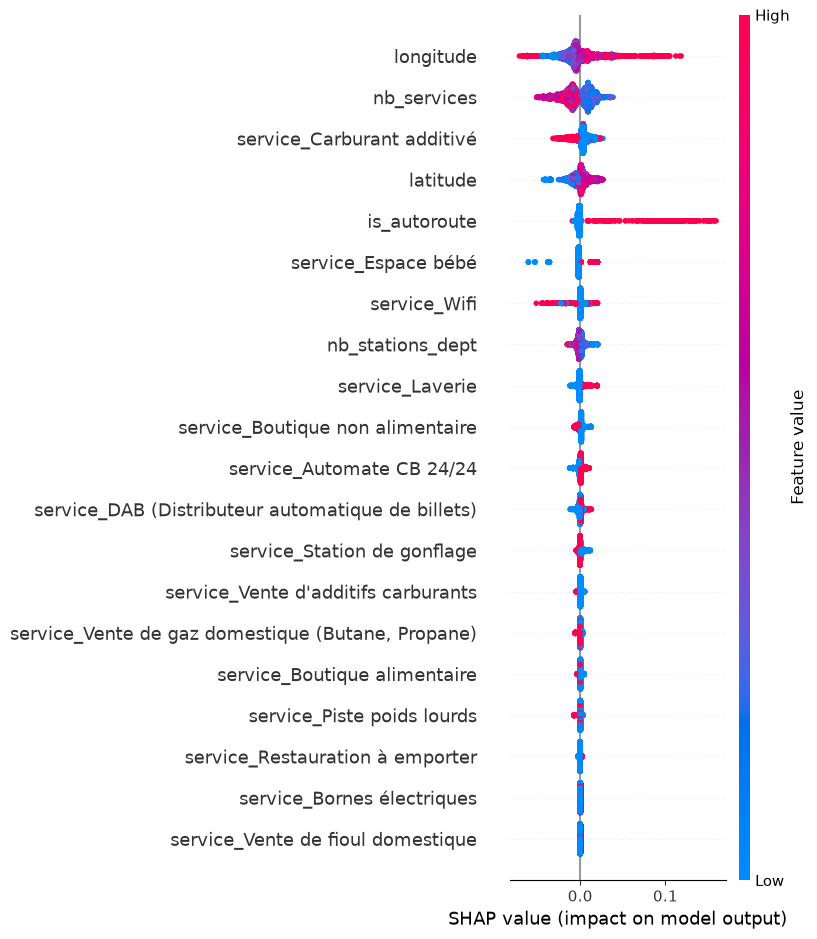

In [46]:
import shap

explainer = shap.TreeExplainer(arbre_final)
shap_values = explainer.shap_values(X_dev)

shap.summary_plot(shap_values, X_dev)

**Importance moyenne.** Longitude (environ 1,5 centime en moyenne), nombre de services (1,25), « Carburant additivé » (0,7), latitude (0,6), autoroute (0,5). Chaque variable déplace le prix de 1 à 2 centimes au plus en moyenne, ce qui est cohérent avec un R² de 0,19. L'autoroute est 2ᵉ en importance par impureté et 5ᵉ ici : peu de stations sont sur autoroute, mais leur effet est très fort.

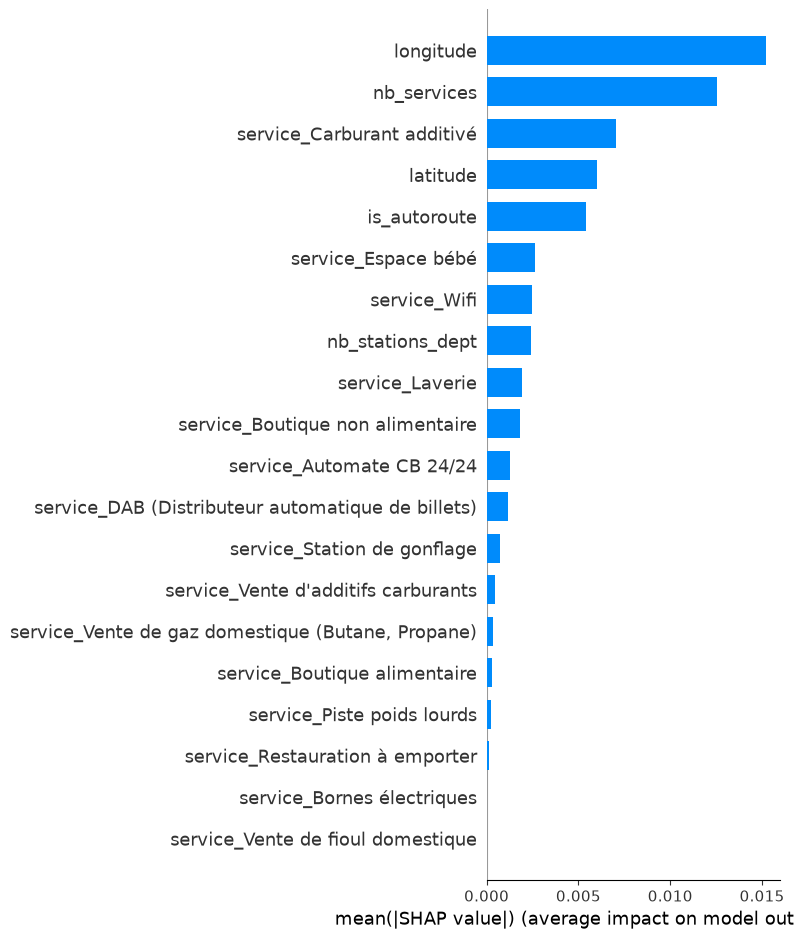

In [47]:
shap.summary_plot(shap_values, X_dev, plot_type="bar")

**Vérification de l'additivité.** Pour la station 0, la prédiction de l'arbre (2,37562) est égale à la valeur de base (prédiction moyenne) plus la somme des effets SHAP. L'explication est un découpage exact de la prédiction.

In [48]:
i = 0
print("Prédiction de l'arbre :", arbre_final.predict(X_dev.iloc[[i]])[0])
print("Valeur de base + somme des effets :", float(np.ravel(explainer.expected_value)[0]) + shap_values[i].sum())

Prédiction de l'arbre : 2.37562
Valeur de base + somme des effets : 2.375619999999999


**Zoom sur le département 94.** 74 stations. Les prix réels sont en moyenne à 2,390 € (écart-type 0,123, de 2,249 à 2,659) et les prédictions à 2,373 € (écart-type 0,042, de 2,251 à 2,427). Le niveau moyen est bon (moins de 2 centimes d'écart), mais le modèle prédit presque la même chose pour toutes les stations du département, alors que leurs prix s'étalent sur 41 centimes. Nos variables décrivent où est la station, pas ce qui la distingue de sa voisine.

In [49]:
masque = (g_final == "94").values
dep94 = pd.DataFrame({"prix": y_final[masque].values, "prediction": pred_final[masque]})
print(len(dep94))
dep94.describe().round(3)

74


,prix,prediction
count,74.000,74.000
mean,2.390,2.373
std,0.123,0.042
min,2.249,2.251
25%,2.250,2.354
50%,2.404,2.372
75%,2.498,2.424
max,2.659,2.427


## Conclusion

| Modèle | Validation croisée (76 départements) MAE | Test final (20 départements) MAE | Test final R² |
|---|---|---|---|
| Baseline (prix moyen) | 5,83 c | 5,94 c | −0,002 |
| Arbre de régression (retenu) | 5,24 c | 5,41 c | 0,186 |
| Forêt aléatoire (testée, non retenue) | 5,06 c | non évaluée | non évaluée |

**À retenir.**
- Les caractéristiques d'une station (position, autoroute, services) expliquent environ un cinquième de la variation de son prix du gazole, et réduisent l'erreur d'environ 9 % par rapport à la moyenne nationale.
- Variables qui comptent le plus : la position (longitude, latitude), le nombre de services et l'autoroute.
- Validation par département : un découpage au hasard aurait mélangé des stations voisines entre entraînement et test et donné un score trop beau.

**Limites.**
- Un seul relevé et un test final de 20 départements : l'erreur moyenne par département varie de 3,8 à 10,3 centimes.
- Environ 18 % des stations affichent exactement 2,25 € (probablement une règle de prix commune) et produisent environ 31 % de l'erreur : nos données n'ont ni l'enseigne ni la concurrence directe.
- À l'intérieur d'un département, le modèle ne distingue pas les stations (exemple du 94).
- SHAP décrit le modèle, pas des causes.

**Suite possible.** Une vraie prévision dans le temps sur la table quotidienne par département, quand l'historique sera plus long.